# E121: why does teacher training land far from the fine-tune's weight change?

**The answer.** Teacher training lands its weight change far from the fine-tune's mainly because it trains only the decomposition's U and V, and partly because it uses a third of the fine-tune's learning rate. A plain student trained on the same target at the fine-tune's rate lands as close to the fine-tune as a rerun does. The teacher-trained change is a different change, not the fine-tune's plus an idle part, and it also moves the trigger's logits differently. Started from the fine-tune's least-squares split, the same training stays close and matches the fine-tuned model better.

Full record, scoring and provenance: `reports/analyses/2026-11-06_analysis_e121-copy-gap-ladder.md`.


## What we were trying to test

**Teacher training** copies a fine-tuned model into the decomposition. Only the subcomponents' U and V train, with Γ and Δ frozen, on the KL divergence from the fine-tuned model. On the emoticon task it keeps the fine-tune's behaviour, yet its weight change sits far from the fine-tune's update δW. A rerun of the same fine-tune in another batch order sits much closer. This experiment asks which difference between the two recipes causes that distance.

Teacher training and the fine-tune share their data: the same 32 windows per step, drawn by the same sampler, for 1,000 Adam steps. They differ in three things, and the ladder changes one at a time:

- **the target**: a student on all weights, trained on KL to the fine-tuned model at the fine-tune's learning rate of 3e-5. This asks whether any student of the fine-tuned model lands elsewhere.
- **the learning rate**: the same student at teacher training's rate of 1e-5.
- **the parametrisation**: teacher training itself, on U and V at 1e-5.

Two side arms sit beside teacher training. One swaps Adam for plain SGD at 0.01, to ask whether Adam's per-entry steps are the cause. The other starts U and V from δW's **least-squares split**, the least-norm $(dU, dV)$ with $dU\,V^\top + U\,dV^\top \approx \delta W$. It asks whether training pulls a change that starts near δW away from it, or whether the distance is only where training from zero happens to end. That start leaves out δW's part outside the subcomponents, since Δ is frozen.

Every arm trains at two batch orders, neither shared with δW; a rung's value is their mean.

**How each state is read.**

- The **input-weighted cosine** to δW: $\cos(A,B) = \langle A,B\rangle / \sqrt{\langle A,A\rangle\langle B,B\rangle}$, with $\langle A,B\rangle = \sum_m \mathrm{tr}(A_m \Sigma_m B_m^\top)$ over the 24 decomposed matrices. $\Sigma_m$ is the uncentred second moment of W₀'s inputs to matrix $m$, so the cosine compares what the two changes do to the inputs the model sees. 1 means the same change; 0 means unrelated. It is read on 73 held-out task windows and on 256 rows of Pile text. The do-nothing state, W₀, has no change and no cosine.
- The **rerun line**: the mean cosine among δW and two reruns of the fine-tune, 0.83 on task windows. It is how close two runs of the same recipe land.
- **Behaviour** on the held-out windows: the target token's probability at the trigger, and the **teacher gap**, the KL divergence from the fine-tuned model in nats. W₀ reads 0.012 and 5.1 nats; the fine-tune reads 0.999 and 0. A state **keeps the behaviour** if its gap is under a tenth of W₀'s and its target probability is within 0.05 of the fine-tune's.
- The **functional cosine**: the cosine between the state's change in trigger-position logits and the fine-tune's, each centred over the vocabulary. 1 means the same logit change.
- The **remainder split**: write the change $S = k\,\delta W + R$, with $k = \langle S,\delta W\rangle / \langle \delta W,\delta W\rangle$ on task windows. Then run W₀ + $k\,\delta W$, the state with its remainder $R$ removed. If that still keeps the behaviour, the remainder is idle; if not, it carries behaviour.

**Controls, run first.** The job reread the earlier experiment's saved cosines to within 5e-8. It regenerated the fine-tune, which matched the saved δW at a Frobenius cosine of 0.999999. It regenerated teacher training at two orders, which matched the saved states to the same precision and the earlier cosines to within 3e-6.


## What we expected, and why

- **Which difference carries the drop.** We leaned towards the parametrisation, at 45%: U and V give Adam a different set of coordinates to step in. The lower rate got 20% and the target 15%. We expected the plain student on the target to land between 0.65 and 0.85, a little below the rerun, since a student only sees the fine-tuned model's outputs.
- **Plain SGD on U and V.** No strong lean: the same as teacher training 40%, further 30%, closer 30%.
- **Starting from the least-squares split.** We leaned towards drifting part of the way back to teacher training's 0.40, at 45%. We expected the start itself to read 0.90 to 0.97.
- **Function.** We leaned, at 55%, that the teacher-trained change would move the trigger logits as much like the fine-tune as a rerun does: "same function, different weights".
- **The remainder.** At a cosine of 0.40 and a size of 0.67, $k$ is about 0.27, and a fine-tune scaled to a quarter should not keep the behaviour. So we leaned that teacher training's remainder carries behaviour, at 70%, and that a rerun's is idle, at 65%.


## Which difference moves the change away from the fine-tune's?

Each column is one arm, left to right in the order the ladder changes things. Small dots are the two batch orders, bars their mean; blue is held-out task windows, orange Pile text. The grey band is the rerun line with the filed margin of 0.05. Open circles are the least-squares split before training.


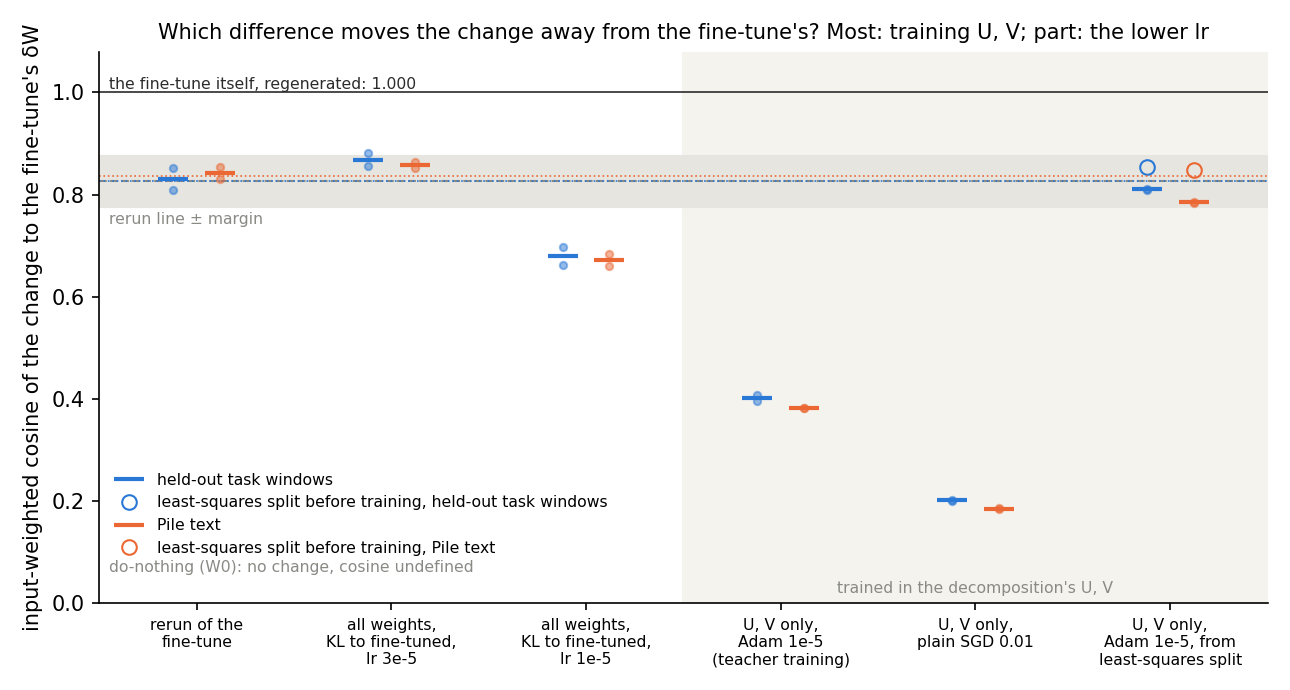

In [1]:
from IPython.display import Image

Image("../experiments/copy_gap_ladder/figures/ladder.png", width=760)


**Reading it.** Most of the distance comes from training only U and V, and the rest from the lower learning rate; the KL target costs nothing. On task windows the rerun line is 0.83, and the plain student on the target at the fine-tune's rate reads 0.87, inside the band. Dropping that student's rate to 1e-5 lowers the cosine to 0.68. Moving the same training into U and V lowers it to 0.40, the earlier experiment's value. Pile text gives the same picture to within 0.03 at every rung.

The side arms say the 0.40 is where training from zero ends, not a limit of U and V. Plain SGD on U and V lands further still, at 0.20. Started from the least-squares split at 0.85, the same training ends at 0.81 on task windows and 0.79 on Pile, while keeping the behaviour. So a change this close to δW is reachable in the decomposition's U and V, and training from zero does not find it.

Caveat: at 1e-5 both students' changes are smaller than δW, half its size for the plain student. Whether a longer run at the lower rate would close the gap was not tested.


## Is teacher training's change the fine-tune's plus an idle part?

Black dots: each trained state's target probability at the trigger. Green squares: the same state with its remainder removed, that is W₀ plus $k\,\delta W$, with $k$ printed beside them. The dashed line is the filed bar for keeping the behaviour; the lines above and below are the fine-tune and the do-nothing state.


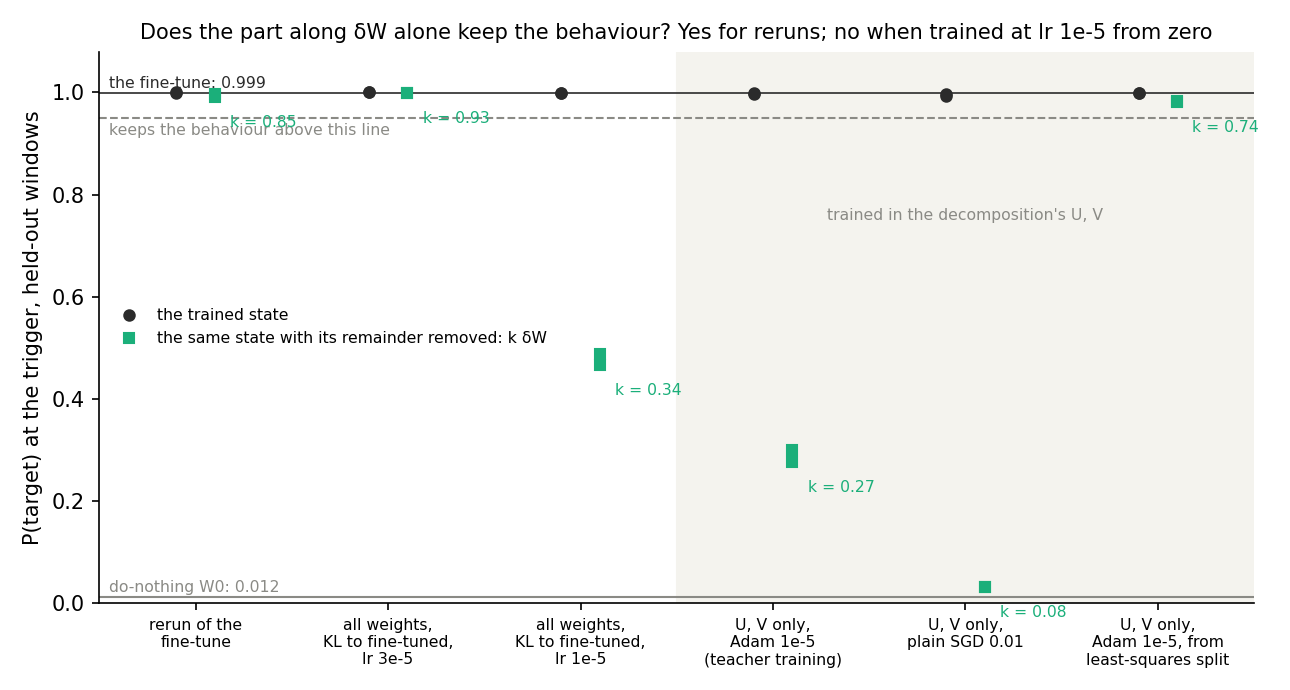

In [2]:
from IPython.display import Image

Image("../experiments/copy_gap_ladder/figures/remainder.png", width=760)


**Reading it.** No: teacher training's remainder carries most of the behaviour, so its change is a different change that does the fine-tune's job. Removing the remainder leaves about a quarter of δW, and the target probability falls from 0.998 to between 0.28 and 0.30. The teacher gap rises from 0.03 to about 1.7 nats, a third of W₀'s. For a rerun, $k$ is 0.80 to 0.89 and the target probability stays at 0.99 or above: its remainder is idle. The same holds for the plain student at the fine-tune's rate and for the start from the least-squares split.

The break already appears with plain weights at the lower rate. That student's own change keeps the behaviour, but without its remainder the target probability is 0.47 to 0.49. So needing the remainder is not special to the decomposition's parametrisation.

Caveat: $k$ is one number for all 24 matrices. A fit per matrix could leave a smaller remainder; it was not run.


## Does teacher training at least reproduce the fine-tune's change in the trigger logits?

Each dot is one batch order's functional cosine, and the bar is their mean. The grey band is the rerun's mean with the filed margin of 0.10, which is the larger of 0.05 and the spread between batch orders. The open circle is the least-squares split before training.


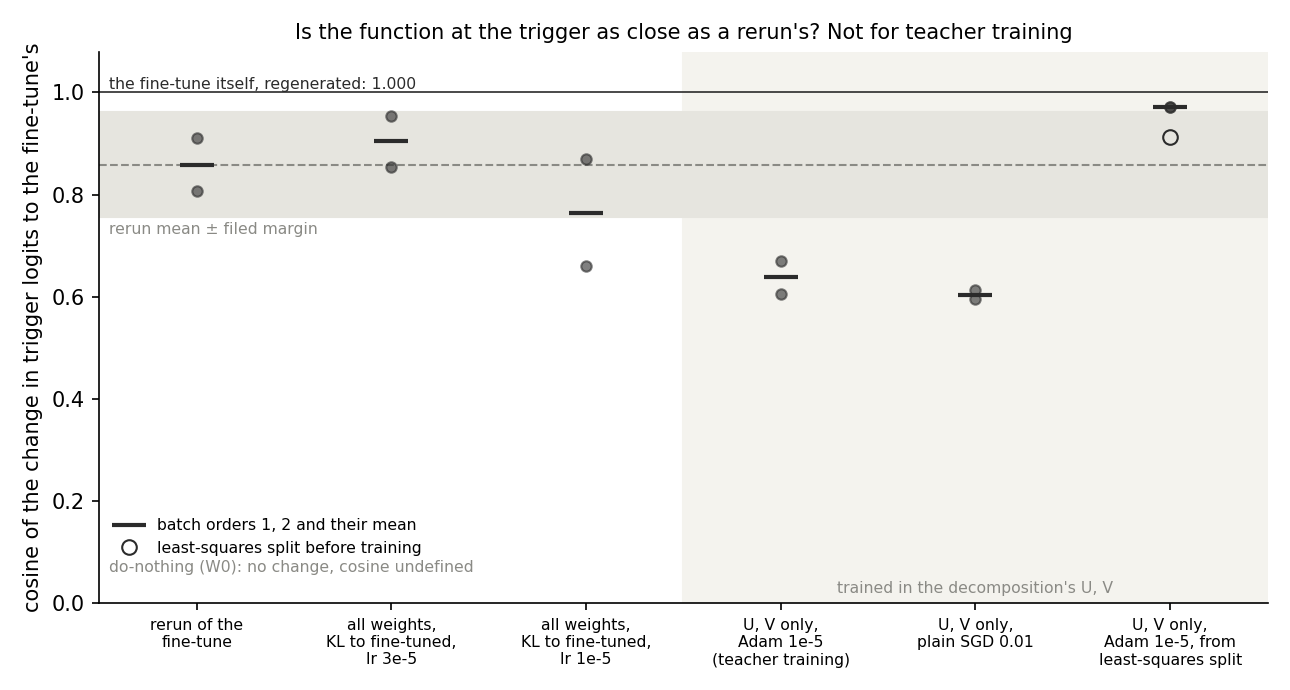

In [3]:
from IPython.display import Image

Image("../experiments/copy_gap_ladder/figures/function.png", width=760)


**Reading it.** No: teacher training changes the trigger logits less like the fine-tune than a rerun does. Its functional cosine averages 0.64, against a rerun mean of 0.86, below the band. The plain student at the fine-tune's rate reads 0.90, and the start from the least-squares split ends at 0.97, both at or above the rerun. Plain SGD on U and V reads 0.60, close to teacher training. The plain student at the lower rate averages 0.76, but its two orders read 0.66 and 0.87, so that rung is noisy.

So teacher training keeps the target token's probability, but the rest of its logit change at the trigger differs from the fine-tune's. "Same function, different weights" does not hold at this position.


## Amendment 1: is the close copy faithful?

**The answer.** Not decided. The three standard teacher-trained copies pass the adversarial check, at 0.97 to 1.00 times W₀'s adversarial KL. The least-squares split before training reads 1.57, and both copies trained from it read 1.55 to 1.57. All three sit above leaving the fine-tune in Δ, at 1.39, and between the pass and fail lines, so the filed outcome is no call. The direction repeats the broad lowercase task: the start that stays close to the fine-tune is less faithful than doing nothing, and training from it does not repair that.

**Why it was run.** The start from the least-squares split keeps the copy close to δW, as the first figure showed. On a broad lowercase fine-tune, E122 found that the same start fails the adversarial check badly: it read 8.33, against 4.79 for that update left in Δ. The standard copy there read 2.17. Does the same happen on the narrow emoticon update?

**The check.** A mask adversary of 20 steps attacks each of two 128-row blocks of Pile text. It maximises the KL divergence of the CI-masked model from the target model. The ratio is the state's adversarial KL over W₀'s: 1 means the state's decomposition is as hard to break as the released one. On this card E34's lines are pass at or under 1.24 and fail at or over 1.81, with the target's probability at least 0.9. E39's fixed lines, 1.40 and 1.61, are drawn beside.

**What we expected.** The standard copies near 1, as E34 read them. The split start and its copies somewhere between 1.3 and 3.0, leaning towards a fail as on the lowercase task.

**The states.** The do-nothing state leaves the whole fine-tune in Δ. Each copy was retrained by this experiment's recipe and matched its saved change to a Frobenius cosine of 0.9999986. Filled dots are trained copies; open circles are untrained states.


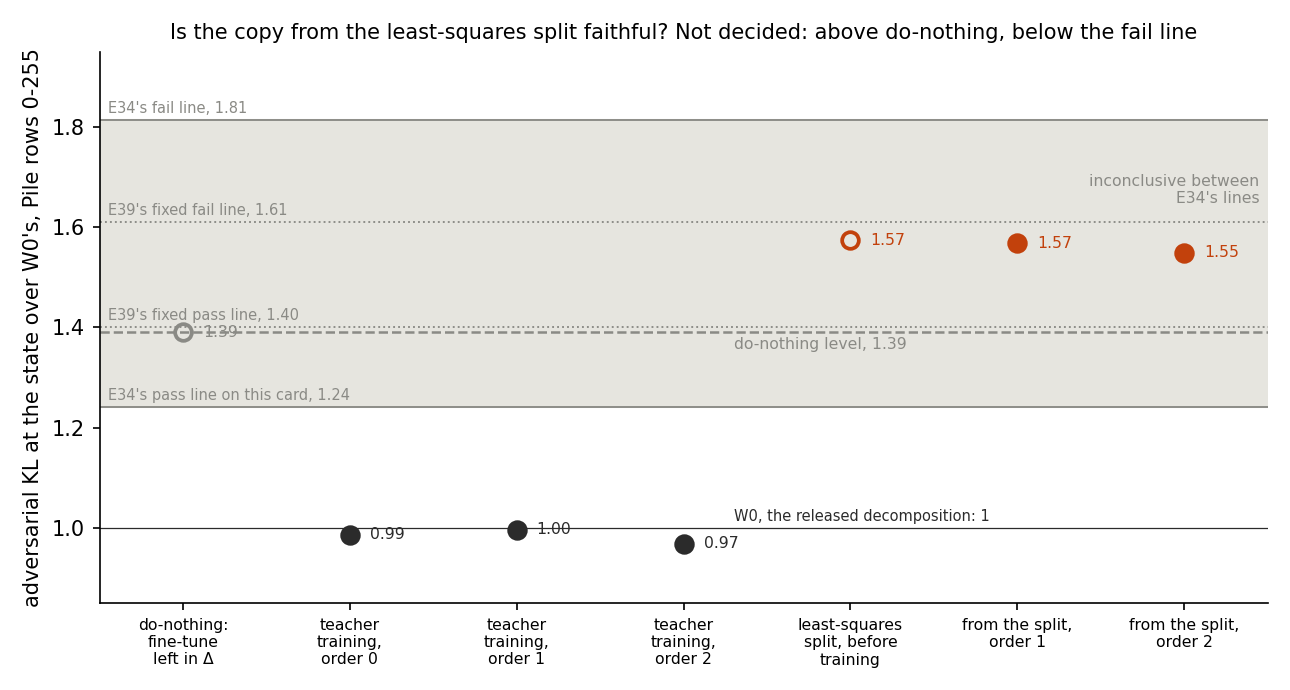

In [4]:
from IPython.display import Image

Image("../experiments/copy_gap_ladder/figures/amend1_faith.png", width=760)


**Reading it.** The standard copies pass and the copies from the least-squares split do not; neither do they fail. The standard copy at three batch orders reads 0.97 to 1.00, as faithful as W₀. The split before training reads 1.57, already above the do-nothing level of 1.39. Training from it to the fine-tuned model's outputs leaves it there, at 1.55 and 1.57. All three sit in the inconclusive band under both line sets.

The power is limited by the task. The do-nothing state itself does not fail, so a pass by a copy could not be told apart from leaving the update in Δ. Only a fail at 1.81 would have been decisive.

What the figure does show is an ordering: standard copies at W₀'s level, the do-nothing state above them, and every state from the split above that. E122 read the same order on the lowercase task, at a far larger scale. So on both a narrow and a broad update, the start that keeps the change close to the fine-tune in weights is less faithful than leaving the update in Δ. Teacher training from that start keeps the excess, while standard teacher training reaches its faithfulness by moving away from δW. Why the split start is less faithful was not tested here; E127 is reading it.

The controls reproduced E34's earlier readings of W₀, the order-0 copy and the do-nothing state exactly.


## What we learned

Teacher training is the project's working way to carry a fine-tune into the decomposition. This run says it reproduces the fine-tune's target behaviour with a different weight change and a different logit change at the trigger. The cause is the path: training U and V from zero, at the lower rate, ends far from δW. It is neither distillation itself, since a plain student of the fine-tuned model lands as close as a rerun, nor a limit of U and V, since starting from the least-squares split stays close. Claims about teacher-trained decompositions should say "keeps the target's probability", not "reproduces the update" or "the same function". Why the lower rate and the U, V coordinates lead there was not measured.

## How compelling is the evidence

One task, the emoticon trigger, with one fine-tune as the teacher. Two batch orders per arm, which agree to within 0.05 on the weight cosines, the filed margin on both input sets. The controls reproduced the earlier states and readings to within 3e-6. The weight cosine is blind to anything downstream of each matrix's output, such as two changes cancelling. The functional cosine sees only the trigger position. The remainder split uses one $k$ for all 24 matrices.

## Surprises

- **The function differs too.** We leaned that teacher training would match the fine-tune's logit change as closely as a rerun; it reads 0.64 against 0.86.
- **The least-squares split's start read 0.85, below the filed 0.90 to 0.97.** The start leaves out δW's part outside the subcomponents; whether that accounts for the shortfall was not checked.
- **From that start, training lowered the teacher gap eightfold below teacher training's.** It reached 0.0035 nats against 0.029, while its cosine fell by only 0.04 to 0.06.
- **The plain student on the target landed slightly closer to δW than a rerun**, at 0.87, above its filed range of 0.65 to 0.85.
- Two expected values for W₀ were off: its teacher gap read 5.1 nats against a filed 5.2 to 5.5, and its target probability 0.012 against about 0.004. No rule reads them except through the keeps-the-behaviour bar.

## What next

- **The plain student and teacher training for 3,000 steps at 1e-5, or teacher training at 3e-5.** If the cosine rises to the rerun line, the rate's share of the gap is too little training; if not, the lower rate finds a different change.
- **A per-matrix remainder split** and a breakdown of $S - \delta W$ along the input directions. If the remainder sits in directions the inputs rarely use, the different change matters less than its cosine suggests.
- **Readings built on teacher-trained decompositions, rerun from the least-squares start.** If a reading changes, it depended on the path, not on the fine-tune.


## Scorecard

Rungs: R0 rerun, R1 plain student at 3e-5, R2 plain student at 1e-5, R3 teacher training, R3b plain SGD on U and V, R4 teacher training from the least-squares split. Task windows / Pile.

| id | claim | read | verdict | lean |
|---|---|---|---|---|
| P1 | which rung carries the drop from the rerun line to R3 | drops R1 −0.04 / −0.02, R2 0.19 / 0.19, R3 0.28 / 0.29 | **R3** on both sets | R3, 45%: as leaned |
| P2 | R3b against R3 | 0.20 / 0.18 against 0.40 / 0.38 | **further than the copy** | same 40%: against the lean |
| P3 | R4: stays, drifts, or no power | start 0.85 / 0.85, end 0.81 / 0.79 | **depends on the inputs**: stays / drifts part way | drifts part way 45%: half |
| P4 | R3's function against a rerun's | 0.64 against 0.86, margin 0.10 | **further than a rerun** | as close 55%: against the lean |
| P5 | remainder idle or carrying behaviour | R0, R1, R4 idle; R2, R3, R3b carry | **R3 carries, R0 idle** | as leaned |

Filed expected ranges missed:

- R1: 0.87 / 0.86 against 0.65 to 0.85.
- R4's start: 0.85 / 0.85 against 0.90 to 0.97 and 0.86 to 0.95.
- R3's functional cosine: 0.64 against 0.70 to 0.95.
- W₀'s gap and target probability, under Surprises.

Every control passed.

Amendment 1, the adversarial check: standard copies, set R3, at three orders; copies from the least-squares split, set R4, at two.

| id | claim | read | verdict | lean |
|---|---|---|---|---|
| A1 | R3 and R4 under the check | R3 0.99 / 1.00 / 0.97, all pass; R4 1.57 / 1.55, both inconclusive; same sets under E39's lines | **no call: R3 pass, R4 inconclusive** | pull apart 50%, no call 20% |

Every Amendment 1 control passed and every filed expected value held.


## Not run

- Longer training, or teacher training and the start from the least-squares split at the fine-tune's rate of 3e-5.
- A plain-weights student with SGD.
- A per-matrix $k$; the functional cosine at positions other than the trigger.
- Amendment 1 ran the adversarial check on the standard copies, the split start and its copies only. Not run: the check on the rerun, the plain students and the SGD arm; its stochastic half; other Pile rows and adversary seeds; where along the text the excess sits.
- Why the split start is less faithful than the do-nothing state, and an adjoint-split start beside it; E127 is reading the cause.
- The other two task families of the earlier experiment, and the Pile-text teacher-training arm.
- A breakdown of the gap along the input directions and the subcomponents' write directions.

## Provenance

Plan `reports/plans/2026-11-06_plan_e121-copy-gap-ladder.md`; filed predictions `experiments/copy_gap_ladder/results/predictions.json`; results `experiments/copy_gap_ladder/results/copy_gap_ladder.json`; code `experiments/copy_gap_ladder/{run,rules,plot}.py`. MATS cluster `debug` QoS, one L40, job 54638, 18:38:53 to 18:57:28 on 2026-11-06, about 19 minutes, $0, peak host memory 7.0 GB. Amendment 1: plan section "Amendment 1", filed `experiments/copy_gap_ladder/results/predictions_amend1.json`, results `results/copy_gap_ladder_amend1.json`, code `amend1.py`; `debug` L40, jobs 54786 and 54815, $0.
